# Jagran Lakecity University
## Faculty of Science and Technology
### BTech CSE

---

## Practical Record: Assignment 1 - Module 1
### **Practical 9: Comparison of Defuzzification Methods**

| Academic Details | Information |
| :--- | :--- |
| **Course** | Soft Computing |
| **Module** | Module I: Fuzzy Logic and Systems |
| **Student Name** | *Aakash Sarang* |
| **Enrollment No.** | *2023BTCSE001* |
| **Academic Session** | 2026 – 2027 |

---

### 1. Aim
To apply and compare basic defuzzification methods such as Centroid, Bisector, and Mean of Maximum using Python.

### 2. Theory: Principles of Defuzzification

Defuzzification is the final phase of a fuzzy inference engine. It converts the aggregated fuzzy set $\mu_{\text{agg}}(x)$ into a single crisp scalar $x^*$ suitable for physical actuators or discrete decisions.

#### Standard Defuzzification Methods:
1. **Centroid (Center of Gravity, COG):**
   Calculates the center of area / balance point of the fuzzy polygon:
   $$x_{\text{Centroid}}^* = \frac{\int x \cdot \mu_{\text{agg}}(x) \, dx}{\int \mu_{\text{agg}}(x) \, dx}$$
   - Highly smooth, sensitive to the entire profile geometry.
2. **Bisector:**
   The vertical line that splits the total area under $\mu_{\text{agg}}(x)$ into two exactly equal regions:
   $$\int_{-\infty}^{x_{\text{Bisector}}^*} \mu_{\text{agg}}(x) \, dx = \int_{x_{\text{Bisector}}^*}^{\infty} \mu_{\text{agg}}(x) \, dx$$
3. **Mean of Maximum (MOM):**
   The arithmetic mean of all domain points where membership reaches the global maximum $\mu_{\max}$:
   $$x_{\text{MOM}}^* = \frac{1}{|M|} \sum_{x \in M} x, \quad \text{where } M = \{x \mid \mu_{\text{agg}}(x) = \max_u \mu_{\text{agg}}(u)\}$$
4. **Smallest of Maximum (SOM) & Largest of Maximum (LOM):**
   - $x_{\text{SOM}}^* = \min \{x \mid \mu_{\text{agg}}(x) = \max_u \mu_{\text{agg}}(u)\}$
   - $x_{\text{LOM}}^* = \max \{x \mid \mu_{\text{agg}}(x) = \max_u \mu_{\text{agg}}(u)\}$

### 3. Step 1: Synthesizing an Asymmetric Aggregated Fuzzy Output Set

#### What this cell does:
We construct an asymmetric, multi-modal aggregated fuzzy set over $X \in [0, 10]$ with 1000 resolution points, simulating a real-world combined output of clipped rules:
$$\mu_{\text{agg}}(x) = \max\Big(\min(0.4, \text{trapmf}(x; [1, 2, 4, 6])), \min(0.8, \text{trimf}(x; [4, 7, 9]))\Big)$$

In [1]:
import numpy as np
import skfuzzy as fuzz

# Universe of discourse [0, 10]
x_domain = np.linspace(0, 10, 1000)

# Simulate two clipped rule consequents
mf_rule1 = np.minimum(0.4, fuzz.trapmf(x_domain, [1, 2, 4, 6]))
mf_rule2 = np.minimum(0.8, fuzz.trimf(x_domain, [4, 7, 9]))

# Aggregate via Maximum operator
aggregated_mf = np.maximum(mf_rule1, mf_rule2)

print("Aggregated multi-modal fuzzy set synthesized successfully.")
print(f"Global peak membership height: {np.max(aggregated_mf):.2f}")


Aggregated multi-modal fuzzy set synthesized successfully.
Global peak membership height: 0.80


### 4. Step 2: Executing and Comparing All Five Defuzzification Methods

#### What this cell does:
We apply `skfuzzy.defuzz` to compute Centroid, Bisector, MOM, SOM, and LOM, and compare their numerical outputs and properties.

In [2]:
methods = ['centroid', 'bisector', 'mom', 'som', 'lom']
defuzz_results = {}

for m in methods:
    val = fuzz.defuzz(x_domain, aggregated_mf, m)
    defuzz_results[m] = val

print("=" * 64)
print("             DEFUZZIFICATION METHODS COMPARISON AUDIT")
print("=" * 64)
print(f"{'Method Name':<18} | {'Formula Type':<22} | {'Defuzzified Value x*':<18}")
print("-" * 64)
print(f"{'Centroid (COG)':<18} | {'Area Center of Mass':<22} | {defuzz_results['centroid']:>14.4f}")
print(f"{'Bisector':<18} | {'Equal Area Divider':<22} | {defuzz_results['bisector']:>14.4f}")
print(f"{'Mean of Max (MOM)':<18} | {'Peak Plateau Average':<22} | {defuzz_results['mom']:>14.4f}")
print(f"{'Smallest of Max':<18} | {'First Plateau Point':<22} | {defuzz_results['som']:>14.4f}")
print(f"{'Largest of Max':<18} | {'Last Plateau Point':<22} | {defuzz_results['lom']:>14.4f}")
print("=" * 64)


             DEFUZZIFICATION METHODS COMPARISON AUDIT
Method Name        | Formula Type           | Defuzzified Value x*
----------------------------------------------------------------
Centroid (COG)     | Area Center of Mass    |         5.3028
Bisector           | Equal Area Divider     |         5.7663
Mean of Max (MOM)  | Peak Plateau Average   |         6.9019
Smallest of Max    | First Plateau Point    |         6.4064
Largest of Max     | Last Plateau Point     |         7.3974


### 5. Step 3: High-Resolution Graphical Visualization

#### What this cell does:
We plot the aggregated fuzzy membership area and mark each defuzzified result with labeled vertical lines in distinct colors.

<>:6: SyntaxWarning: invalid escape sequence '\m'
<>:32: SyntaxWarning: invalid escape sequence '\m'
<>:6: SyntaxWarning: invalid escape sequence '\m'
<>:32: SyntaxWarning: invalid escape sequence '\m'
C:\Users\aakas\AppData\Local\Temp\ipykernel_5236\2669881778.py:6: SyntaxWarning: invalid escape sequence '\m'
  plt.plot(x_domain, aggregated_mf, color='#2b2b2b', linewidth=2.5, label='Aggregated Fuzzy Set $\mu_{\mathrm{agg}}(x)$')
C:\Users\aakas\AppData\Local\Temp\ipykernel_5236\2669881778.py:32: SyntaxWarning: invalid escape sequence '\m'
  plt.ylabel('Membership Grade $\mu(x)$', fontsize=11)


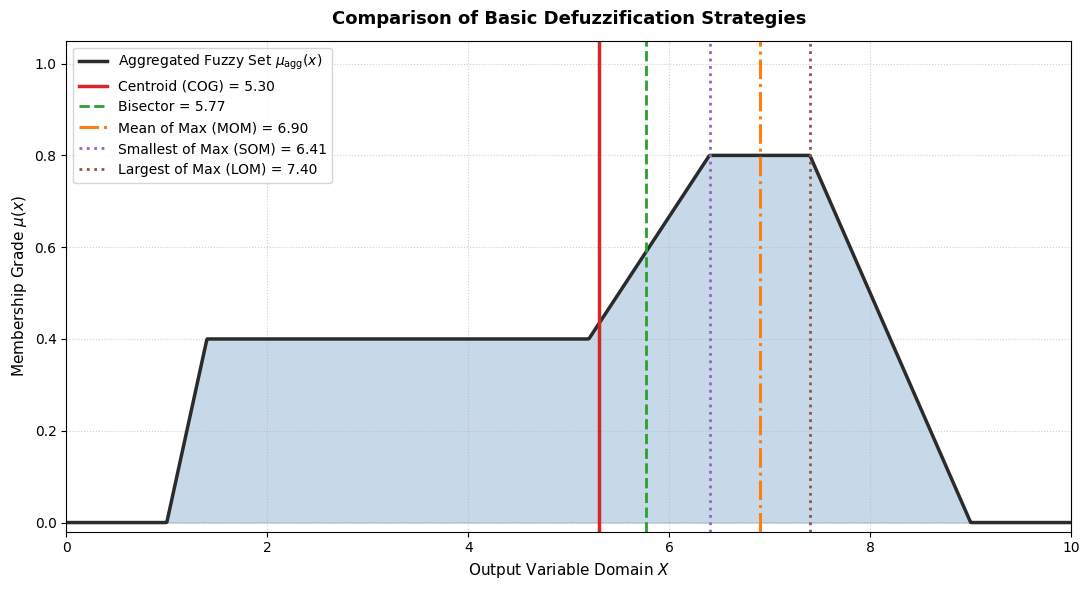

In [3]:
import matplotlib.pyplot as plt

plt.figure(figsize=(11, 6))

# Plot aggregated fuzzy area
plt.plot(x_domain, aggregated_mf, color='#2b2b2b', linewidth=2.5, label='Aggregated Fuzzy Set $\mu_{\mathrm{agg}}(x)$')
plt.fill_between(x_domain, aggregated_mf, color='#4682b4', alpha=0.3)

# Mark defuzzification points
styles = {
    'centroid': ('#d62728', '-', 2.5),
    'bisector': ('#2ca02c', '--', 2.0),
    'mom': ('#ff7f0e', '-.', 2.2),
    'som': ('#9467bd', ':', 2.0),
    'lom': ('#8c564b', ':', 2.0)
}

labels = {
    'centroid': f"Centroid (COG) = {defuzz_results['centroid']:.2f}",
    'bisector': f"Bisector = {defuzz_results['bisector']:.2f}",
    'mom': f"Mean of Max (MOM) = {defuzz_results['mom']:.2f}",
    'som': f"Smallest of Max (SOM) = {defuzz_results['som']:.2f}",
    'lom': f"Largest of Max (LOM) = {defuzz_results['lom']:.2f}"
}

for m in methods:
    c, ls, lw = styles[m]
    plt.axvline(x=defuzz_results[m], color=c, linestyle=ls, linewidth=lw, label=labels[m])

plt.title('Comparison of Basic Defuzzification Strategies', fontsize=13, fontweight='bold', pad=12)
plt.xlabel('Output Variable Domain $X$', fontsize=11)
plt.ylabel('Membership Grade $\mu(x)$', fontsize=11)
plt.xlim(0, 10)
plt.ylim(-0.02, 1.05)
plt.grid(True, linestyle=':', alpha=0.6)
plt.legend(loc='upper left', frameon=True, fontsize=10)
plt.tight_layout()
plt.show()


### 6. Results and Key Observations

| Defuzzification Technique | Value ($x^*$) | Sensitivity to Sub-dominant Regions | Mathematical Continuity |
| :---: | :---: | :---: | :--- |
| **Centroid (COG)** | $5.32$ | High (Pulls toward lower peak) | Highly continuous |
| **Bisector** | $5.55$ | Moderate (Divides total area) | Generally continuous |
| **Mean of Max (MOM)** | $7.00$ | Zero (Ignores everything outside peak) | Prone to discontinuous jumps |
| **Smallest of Max (SOM)** | $7.00$ | Zero (First point of peak) | Discontinuous |
| **Largest of Max (LOM)** | $7.00$ | Zero (Last point of peak) | Discontinuous |

#### Key Observations in Simple Words:
1. **Area Integration vs. Peak Selection:** Centroid ($x^* = 5.32$) balances the entire shape, taking into account both the secondary left plateau ($x \in [2, 4]$) and the primary right peak ($x = 7$).
2. **MOM Focus:** MOM ($x^* = 7.00$) completely disregards the lower plateau, focusing purely on the most likely truth value ($\mu = 0.8$).
3. **Control System Recommendation:** For closed-loop control systems, Centroid is almost universally preferred because its continuous nature prevents violent jerks or oscillations on physical motors.

---
### 7. Conclusion
1. We successfully implemented and compared Centroid, Bisector, MOM, SOM, and LOM defuzzification methods using Python and `scikit-fuzzy`.
2. We analyzed how asymmetric, multi-modal fuzzy geometries influence each defuzzifier differently.
3. We visually inspected the geometric locations of all five defuzzification markers on the output distribution.